# g-Laplacian solver — decomposition-coordination method for Young functions $G$, on general 2D domains

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jfbonder/glaplace/blob/main/notebooks/glaplace_colab.ipynb)

We solve, with $g=G'$ and $G(x,\cdot)$ a Young function,
$$-\mathrm{div}\Big(g(x,|\nabla u|)\frac{\nabla u}{|\nabla u|}\Big)=f\ \text{in }\Omega,\qquad u=u_D\ \text{on }\partial\Omega,$$
i.e. we minimise $\int_\Omega G(x,|\nabla u|)-\int_\Omega fu$, with the iteration (augmented Lagrangian / ADMM, parameter $r>0$):

1. $r(-\Delta u_n)=f+\mathrm{div}(\eta_n-r\nu_{n-1})$  (linear, same matrix at every step → factorised once),
2. $\nu_n=t\,w/|w|$, $w=\eta_n/r+\nabla u_n$, where $t\ge 0$ solves $g(x,t)+rt=r|w|$  (pointwise scalar equation),
3. $\eta_{n+1}=\eta_n+r(\nabla u_n-\nu_n)$.

For $G=t^p/p$ this is the method of Aragón–Fernández Bonder–Rubio for the $p$-Laplacian. **Run all cells.**

## 1. Package source (self-contained)

In [1]:
!pip -q install triangle meshio sympy 2>&1 | tail -1
!mkdir -p glaplace

In [2]:
%%writefile glaplace/__init__.py
"""glaplace: g-Laplacian solver (decomposition-coordination / ADMM + P1 FEM) on general 2D domains.

-div( g(x,|grad u|) grad u/|grad u| ) = f,  g = dG/dt,  G a Young function (p-q, p log^a, exp, two-phase, ...).
Built from the p(x)-Laplacian code `pxlaplace` (Aragon, Fernandez Bonder, Rubio).
"""
from .mesh import (Mesh, rectangle_mesh, polygon_mesh, sdf_mesh, disk_mesh,
                   from_txt, from_meshio, boundary_nodes_from_triangles)
from .fem import P1Space
from .young import (Young, PowerLaw, PLog, Exp, ExpLiteral, Custom, Sum, from_expr, pq, check_young)
from .solver import GLaplaceSolver, solve, SolveResult
from .nonlinear import solve_scalar, update_nu
from . import exact

__all__ = ["Mesh", "rectangle_mesh", "polygon_mesh", "sdf_mesh", "disk_mesh", "from_txt", "from_meshio",
           "boundary_nodes_from_triangles", "P1Space", "Young", "PowerLaw", "PLog", "Exp", "ExpLiteral", "Custom",
           "Sum", "from_expr", "pq", "check_young", "GLaplaceSolver", "solve", "SolveResult", "solve_scalar",
           "update_nu", "exact"]

Writing glaplace/__init__.py


In [3]:
%%writefile glaplace/mesh.py
"""Triangular meshes for arbitrary 2D domains.

A :class:`Mesh` only needs ``vertices (Nn,2)``, ``triangles (Nt,3)`` and the
indices of the Dirichlet (boundary) nodes -- exactly the three arrays the
MatLab code reads (vertex_coordinates, elem_vertices, dirichlet).  Everything
else in the package is domain independent, so any mesher can be plugged in.
"""
from __future__ import annotations
from dataclasses import dataclass, field
import numpy as np


@dataclass
class Mesh:
    vertices: np.ndarray          # (Nn, 2) float
    triangles: np.ndarray         # (Nt, 3) int, counter-clockwise
    dirichlet: np.ndarray         # (Nd,)   int, boundary node indices

    def __post_init__(self):
        self.vertices = np.ascontiguousarray(self.vertices, dtype=float)
        self.triangles = np.ascontiguousarray(self.triangles, dtype=np.int64)
        self.dirichlet = np.unique(np.asarray(self.dirichlet, dtype=np.int64))
        self._orient()

    def _orient(self):
        """Make every triangle counter-clockwise (positive area)."""
        v = self.vertices[self.triangles]
        d = ((v[:, 1, 0] - v[:, 0, 0]) * (v[:, 2, 1] - v[:, 0, 1])
             - (v[:, 2, 0] - v[:, 0, 0]) * (v[:, 1, 1] - v[:, 0, 1]))
        flip = d < 0
        if flip.any():
            self.triangles[flip] = self.triangles[flip][:, [0, 2, 1]]

    @property
    def n_nodes(self): return self.vertices.shape[0]
    @property
    def n_elems(self): return self.triangles.shape[0]

    def plot(self, u=None, ax=None, **kw):
        import matplotlib.pyplot as plt
        import matplotlib.tri as mtri
        tri = mtri.Triangulation(self.vertices[:, 0], self.vertices[:, 1], self.triangles)
        if ax is None:
            ax = plt.gca()
        if u is None:
            ax.triplot(tri, lw=0.4, **kw)
        else:
            c = ax.tripcolor(tri, u, shading="gouraud", **kw)
            ax.figure.colorbar(c, ax=ax)
        ax.set_aspect("equal")
        return ax


def boundary_nodes_from_triangles(triangles) -> np.ndarray:
    """Nodes on edges that belong to exactly one triangle (the boundary)."""
    t = np.asarray(triangles)
    edges = np.vstack([t[:, [0, 1]], t[:, [1, 2]], t[:, [2, 0]]])
    edges = np.sort(edges, axis=1)
    uniq, counts = np.unique(edges, axis=0, return_counts=True)
    return np.unique(uniq[counts == 1])


# --------------------------------------------------------------------------
# Rectangle (same layout as gen_mesh_rectangle.m, but in memory)
# --------------------------------------------------------------------------
def rectangle_mesh(n: int, m: int | None = None, xmin=0.0, xmax=1.0, ymin=0.0, ymax=1.0) -> Mesh:
    """Uniform mesh of [xmin,xmax]x[ymin,ymax]: n x m cells, 2 triangles each."""
    m = n if m is None else m
    x = np.linspace(xmin, xmax, n + 1)
    y = np.linspace(ymin, ymax, m + 1)
    X, Y = np.meshgrid(x, y)                      # row i -> y_i, col j -> x_j
    V = np.column_stack([X.ravel(), Y.ravel()])
    idx = np.arange((n + 1) * (m + 1)).reshape(m + 1, n + 1)
    a, b = idx[:-1, :-1].ravel(), idx[:-1, 1:].ravel()
    c, d = idx[1:, 1:].ravel(), idx[1:, :-1].ravel()
    T = np.vstack([np.column_stack([a, b, d]), np.column_stack([b, c, d])])
    bd = np.concatenate([idx[0, :], idx[-1, :], idx[:, 0], idx[:, -1]])
    return Mesh(V, T, bd)


# --------------------------------------------------------------------------
# Polygon (with holes) via Shewchuk's Triangle (optional dependency)
# --------------------------------------------------------------------------
def polygon_mesh(outer, holes=(), hole_points=(), max_area=None, min_angle=25.0) -> Mesh:
    """Quality triangulation of a polygon with optional polygonal holes.

    outer       : (k,2) vertices of the outer boundary (any orientation)
    holes       : iterable of (k_i,2) arrays, boundaries of the holes
    hole_points : (not needed; a point inside every hole is computed automatically)
    max_area    : maximum triangle area (controls resolution)
    Requires the ``triangle`` package (pip install triangle).
    """
    try:
        import triangle as tr
    except ImportError as e:                                   # pragma: no cover
        raise ImportError("polygon_mesh needs `pip install triangle`; "
                          "alternatively use sdf_mesh()") from e
    outer = np.asarray(outer, float)
    pts, segs, hpts = [outer], [], []
    off = len(outer)
    segs.append(np.column_stack([np.arange(off), (np.arange(off) + 1) % off]))
    for h in holes:
        h = np.asarray(h, float)
        k = len(h)
        segs.append(np.column_stack([off + np.arange(k), off + (np.arange(k) + 1) % k]))
        pts.append(h)
        hpts.append(_interior_point(h))
        off += k
    A = dict(vertices=np.vstack(pts), segments=np.vstack(segs))
    if hpts:
        A["holes"] = np.array(hpts)
    opts = f"pq{min_angle:g}"
    if max_area is not None:
        opts += f"a{max_area:.10g}"
    B = tr.triangulate(A, opts)
    T = B["triangles"]
    return Mesh(B["vertices"], T, boundary_nodes_from_triangles(T))


def _interior_point(poly):
    """A point strictly inside a simple polygon (centroid of an ear)."""
    n = len(poly)
    from matplotlib.path import Path
    path = Path(poly)
    c = poly.mean(axis=0)
    if path.contains_point(c):
        return c
    for i in range(n):
        tri = poly[[i, (i + 1) % n, (i + 2) % n]]
        p = tri.mean(axis=0)
        if path.contains_point(p):
            return p
    raise ValueError("could not find an interior point of the hole")


# --------------------------------------------------------------------------
# Implicit domains via signed distance function (DistMesh-lite, numpy/scipy)
# --------------------------------------------------------------------------
def sdf_mesh(sdf, bbox, h0, fh=None, seed=0, max_iter=300, fixed=None, verbose=False) -> Mesh:
    """Mesh {sdf<0} with a simplified DistMesh (Persson & Strang, 2004).

    sdf  : callable (N,2)->(N,) signed distance, negative inside
    bbox : (xmin, ymin, xmax, ymax)
    h0   : target edge length
    fh   : optional callable (N,2)->(N,) relative size function (default 1)
    """
    from scipy.spatial import Delaunay
    rng = np.random.default_rng(seed)
    xmin, ymin, xmax, ymax = bbox
    geps = 0.001 * h0
    deps = np.sqrt(np.finfo(float).eps) * h0
    fh = fh or (lambda p: np.ones(len(p)))
    # hexagonal initial grid
    xs = np.arange(xmin, xmax + h0, h0)
    ys = np.arange(ymin, ymax + h0 * np.sqrt(3) / 2, h0 * np.sqrt(3) / 2)
    X, Y = np.meshgrid(xs, ys)
    X[1::2, :] += h0 / 2
    p = np.column_stack([X.ravel(), Y.ravel()])
    p = p[sdf(p) < geps]
    r0 = 1.0 / fh(p) ** 2
    p = p[rng.random(len(p)) < r0 / r0.max()]
    fixed = np.zeros((0, 2)) if fixed is None else np.asarray(fixed, float)
    if len(fixed):
        p = np.vstack([fixed, p])
    nfix = len(fixed)
    pold = np.full_like(p, np.inf)
    Fscale, dt, ttol = 1.2, 0.2, 0.1
    for it in range(max_iter):
        if np.max(np.linalg.norm(p - pold, axis=1) / h0) > ttol:
            pold = p.copy()
            tri = Delaunay(p).simplices
            cen = p[tri].mean(axis=1)
            tri = tri[sdf(cen) < -geps]
            bars = np.unique(np.sort(np.vstack([tri[:, [0, 1]], tri[:, [1, 2]], tri[:, [2, 0]]]), axis=1), axis=0)
        bv = p[bars[:, 0]] - p[bars[:, 1]]
        L = np.linalg.norm(bv, axis=1)
        hb = fh(p[bars].mean(axis=1))
        L0 = hb * Fscale * np.sqrt(np.sum(L ** 2) / np.sum(hb ** 2))
        F = np.maximum(L0 - L, 0)
        Fv = (F / np.maximum(L, 1e-300))[:, None] * bv
        Ftot = np.zeros_like(p)
        np.add.at(Ftot, bars[:, 0], Fv)
        np.add.at(Ftot, bars[:, 1], -Fv)
        Ftot[:nfix] = 0
        p = p + dt * Ftot
        d = sdf(p)
        out = d > 0                                   # project back onto boundary
        if out.any():
            q = p[out]
            dx = (sdf(q + [deps, 0]) - d[out]) / deps
            dy = (sdf(q + [0, deps]) - d[out]) / deps
            p[out] = q - np.column_stack([d[out] * dx, d[out] * dy])
        inside = d < -geps
        if it > 0 and np.max(np.linalg.norm(dt * Ftot[inside], axis=1) / h0, initial=0.0) < 1e-3:
            if verbose:
                print("sdf_mesh converged at iteration", it)
            break
    tri = Delaunay(p).simplices
    tri = tri[sdf(p[tri].mean(axis=1)) < -geps]
    # drop unused nodes
    used = np.unique(tri)
    remap = -np.ones(len(p), int); remap[used] = np.arange(len(used))
    p, tri = p[used], remap[tri]
    return Mesh(p, tri, boundary_nodes_from_triangles(tri))


def disk_mesh(h0=0.05, center=(0.0, 0.0), radius=1.0, **kw) -> Mesh:
    c = np.asarray(center, float)
    sdf = lambda p: np.linalg.norm(p - c, axis=1) - radius
    return sdf_mesh(sdf, (c[0] - radius, c[1] - radius, c[0] + radius, c[1] + radius), h0, **kw)


# --------------------------------------------------------------------------
# Importers
# --------------------------------------------------------------------------
def from_txt(vertex_file, elem_file, dirichlet_file=None, one_based=True) -> Mesh:
    """Read the three text files of the MatLab code (1-based indices by default)."""
    V = np.loadtxt(vertex_file)
    T = np.loadtxt(elem_file, dtype=int)
    s = 1 if one_based else 0
    T = T - s
    if dirichlet_file is None:
        D = boundary_nodes_from_triangles(T)
    else:
        D = np.loadtxt(dirichlet_file, dtype=int) - s
    return Mesh(V, T, D)


def from_meshio(path_or_mesh) -> Mesh:
    """Any format supported by meshio (gmsh .msh, .vtk, .xdmf, ...). Uses the triangle cells."""
    import meshio
    m = meshio.read(path_or_mesh) if isinstance(path_or_mesh, (str, bytes)) or hasattr(path_or_mesh, "__fspath__") else path_or_mesh
    T = m.get_cells_type("triangle")
    return Mesh(m.points[:, :2], T, boundary_nodes_from_triangles(T))

Writing glaplace/mesh.py


In [4]:
%%writefile glaplace/fem.py
"""P1 finite elements on a triangular mesh (fully vectorised)."""
from __future__ import annotations
import numpy as np
import scipy.sparse as sp
from .mesh import Mesh


class P1Space:
    """Piecewise-linear space on ``mesh``.

    Precomputes element areas, the (constant) gradient operators
    Gx, Gy : (Nt x Nn) sparse so that  grad u|_T = (Gx u, Gy u)[T],
    and the stiffness matrix K_ij = int grad(phi_i).grad(phi_j).
    """

    def __init__(self, mesh: Mesh):
        self.mesh = mesh
        V, T = mesh.vertices, mesh.triangles
        self.Nn, self.Nt = mesh.n_nodes, mesh.n_elems
        x, y = V[T, 0], V[T, 1]                      # (Nt,3)
        # b_i = y_j - y_k, c_i = x_k - x_j  (cyclic);  grad phi_i = (b_i, c_i) / (2|T|)
        b = np.column_stack([y[:, 1] - y[:, 2], y[:, 2] - y[:, 0], y[:, 0] - y[:, 1]])
        c = np.column_stack([x[:, 2] - x[:, 1], x[:, 0] - x[:, 2], x[:, 1] - x[:, 0]])
        det = (x[:, 1] - x[:, 0]) * (y[:, 2] - y[:, 0]) - (x[:, 2] - x[:, 0]) * (y[:, 1] - y[:, 0])
        if np.any(det <= 0):
            raise ValueError("degenerate or clockwise triangles in mesh")
        self.area = 0.5 * det
        self.gx = b / det[:, None]                   # (Nt,3) d phi_i / dx on T
        self.gy = c / det[:, None]
        self.bary = V[T].mean(axis=1)                # (Nt,2) barycentres
        rows = np.repeat(np.arange(self.Nt), 3)
        cols = T.ravel()
        self.Gx = sp.csr_matrix((self.gx.ravel(), (rows, cols)), shape=(self.Nt, self.Nn))
        self.Gy = sp.csr_matrix((self.gy.ravel(), (rows, cols)), shape=(self.Nt, self.Nn))
        # K = Gx^T diag(area) Gx + Gy^T diag(area) Gy
        W = sp.diags(self.area)
        self.K = (self.Gx.T @ W @ self.Gx + self.Gy.T @ W @ self.Gy).tocsr()

    # ---- linear forms --------------------------------------------------
    def load_vector(self, f, degree: int = 1) -> np.ndarray:
        """b_i = int f phi_i.  degree=1: one-point barycentre rule (as in the MatLab code;
        exact only for constant f, O(h^2)-consistent); degree=2: 3-point edge-midpoint rule
        (exact for f in P2)."""
        V, T = self.mesh.vertices, self.mesh.triangles
        b = np.zeros(self.Nn)
        if degree == 1:
            val = _eval(f, self.bary)
            contrib = np.repeat((self.area * val / 3.0)[:, None], 3, axis=1)
        elif degree == 2:
            P = V[T]
            mids = [0.5 * (P[:, 1] + P[:, 2]), 0.5 * (P[:, 2] + P[:, 0]), 0.5 * (P[:, 0] + P[:, 1])]
            fm = np.column_stack([_eval(f, m) for m in mids])      # f at midpoint opposite vertex i
            # phi_i at midpoint k = 1/2 if k != i else 0 ; weights area/3
            S = fm.sum(axis=1, keepdims=True) - fm                  # sum over k != i
            contrib = self.area[:, None] / 3.0 * 0.5 * S
        else:
            raise ValueError("degree must be 1 or 2")
        np.add.at(b, T.ravel(), contrib.ravel())
        return b

    def weak_div(self, qx, qy) -> np.ndarray:
        """b_i = int q . grad(phi_i) for an element-wise constant vector field q."""
        return self.Gx.T @ (self.area * qx) + self.Gy.T @ (self.area * qy)

    # ---- evaluation ----------------------------------------------------
    def gradient(self, u):
        """Gradient of the P1 interpolant (constant per element): (qx, qy)."""
        return self.Gx @ u, self.Gy @ u

    def element_values(self, fun_or_const) -> np.ndarray:
        """Evaluate a function at the barycentre of each element (used for p(x))."""
        return _eval(fun_or_const, self.bary, nt=self.Nt)

    def node_values(self, fun_or_const, idx=None) -> np.ndarray:
        P = self.mesh.vertices if idx is None else self.mesh.vertices[idx]
        return _eval(fun_or_const, P)

    # ---- integrals -----------------------------------------------------
    def modular(self, w, p) -> float:
        """J_p(w) = int |w|^p dx for a P1 function w (nodal values) and exponent p
        constant per element (array) or scalar; 3-point edge-midpoint rule."""
        P = w[self.mesh.triangles]                                  # (Nt,3)
        mid = 0.5 * (P + P[:, [1, 2, 0]])                           # values at 3 edge midpoints
        p = np.broadcast_to(np.asarray(p, float), (self.Nt,))
        return float(np.sum(self.area * np.mean(np.abs(mid) ** p[:, None], axis=1)))

    def norm_L2(self, w) -> float:
        """L2 norm of the P1 function with nodal values w.  NOTE: applied to u_h - u(nodes) this is
        ||u_h - I_h u||, not the error ||u_h - u||; use :meth:`l2_error` for the latter."""
        return self.modular(w, 2.0) ** 0.5

    def norm_Lp(self, w, p) -> float:
        p = np.asarray(p, float)
        return self.modular(w, p) ** (1.0 / float(np.max(p)))

    # ---- TRUE errors against an exact solution (quadrature, not nodal) --------
    _QL = np.array([[0.445948490915965, 0.445948490915965, 0.108103018168070],
                    [0.445948490915965, 0.108103018168070, 0.445948490915965],
                    [0.108103018168070, 0.445948490915965, 0.445948490915965],
                    [0.091576213509771, 0.091576213509771, 0.816847572980459],
                    [0.091576213509771, 0.816847572980459, 0.091576213509771],
                    [0.816847572980459, 0.091576213509771, 0.091576213509771]])
    _QW = np.array([0.223381589678011] * 3 + [0.109951743655322] * 3)     # Dunavant degree-4 rule

    def _qpoints(self):
        P = self.mesh.vertices[self.mesh.triangles]                       # (Nt,3,2)
        return self._QL @ P[:, :, 0].T, self._QL @ P[:, :, 1].T            # each (6,Nt)

    def l2_error(self, uh, u_exact, relative=True) -> float:
        """||u - u_h||_{L2(Omega_h)} with a degree-4 rule on every triangle (this is the TRUE error;
        ``norm_L2`` of the nodal difference only measures ||I_h u - u_h||, which can be much smaller)."""
        X, Y = self._qpoints()
        ue = np.asarray(u_exact(X, Y), float)
        uhq = self._QL @ uh[self.mesh.triangles].T
        num = np.sqrt(np.sum(self.area * (self._QW @ (ue - uhq) ** 2)))
        den = np.sqrt(np.sum(self.area * (self._QW @ ue**2))) if relative else 1.0
        return float(num / den)

    def grad_error_Lp(self, uh, grad_exact, p, relative=True) -> float:
        """||grad(u - u_h)||_{L^p(Omega_h)} (p scalar or element-wise array; for variable p the modular
        (int |.|^p)^(1/max p) is returned), degree-4 rule.  grad_exact(x, y) -> (ux, uy)."""
        X, Y = self._qpoints()
        ex, ey = grad_exact(X, Y)
        gx, gy = self.gradient(uh)
        p = np.broadcast_to(np.asarray(p, float), (self.Nt,))
        err = np.sum(self.area * (self._QW @ (np.hypot(ex - gx, ey - gy) ** p)))
        den = np.sum(self.area * (self._QW @ (np.hypot(ex, ey) ** p))) if relative else 1.0
        return float((err / den) ** (1.0 / float(np.max(p))))

    @staticmethod
    def norm_inf(w) -> float:
        return float(np.max(np.abs(w)))


def _eval(fun, pts, nt=None):
    """Evaluate scalar function / constant / array at points (N,2) -> (N,)."""
    n = len(pts)
    if callable(fun):
        try:
            v = np.asarray(fun(pts[:, 0], pts[:, 1]), dtype=float)
            if v.shape == ():
                v = np.full(n, float(v))
        except Exception:
            v = np.array([fun(a, b) for a, b in pts], dtype=float)
        if v.shape != (n,):
            v = np.array([fun(a, b) for a, b in pts], dtype=float)
        return v
    v = np.asarray(fun, dtype=float)
    if v.shape == ():
        return np.full(n, float(v))
    if v.shape != (n,):
        raise ValueError(f"array of shape {v.shape} does not match {n} points")
    return v

Writing glaplace/fem.py


In [5]:
%%writefile glaplace/young.py
"""Young functions  G(x, t)  and their derivatives  g(x, t) = d/dt G(x, t),  t >= 0.

The g-Laplacian is  -div( g(x,|grad u|) grad u/|grad u| ) = f.  A Young function object provides two
vectorised methods

    Gf.G(t, x, y)   -> G(x,y,t)
    Gf.g(t, x, y)   -> g(x,y,t) = dG/dt          (g(0) is understood as the limit g(0+))

where ``t`` is an array of |grad u| values (one per triangle) and ``x, y`` the barycentres of the
triangles (arrays of the same shape; they are only used by x-dependent functions).

Building blocks (all with G(0) = 0, G convex in t) and the algebra:

    PowerLaw(p)            t^p / p                          g = t^(p-1)
    PLog(p, a)             t^p log^a(1+t)                   (p-Laplacian with a logarithmic perturbation)
    Exp()                  e^t - 1 - t                      g = e^t - 1        (does NOT satisfy Delta_2)
    ExpLiteral()           e^t - 1                          g = e^t, g(0+) = 1 (flat where |flux| <= 1: "dead core")
    Custom(G, g)           any pair of callables G(t), g(t)
    from_expr("t**3/3")    G given as a sympy expression in t (needs sympy); g = dG/dt is computed symbolically

    G1 + G2, c*G, w(x,y)*G  (sums with constant or spatially varying non-negative weights), e.g.
    ``PowerLaw(2) + a * PowerLaw(4)`` with ``a = lambda x, y: np.where(x > 0, 1.0, 0.0)`` is a two-phase problem.

``check_young(Gf)`` tests numerically that G(0)=0, g >= 0 and g is non-decreasing (convexity of G).
"""
from __future__ import annotations
import numpy as np


def _arr(t):
    return np.asarray(t, float)


class Young:
    """Base class; subclasses implement ``_G(t)`` and ``_g(t)`` (x-independent) or override ``G``/``g``."""
    __array_ufunc__ = None          # so that  numpy_scalar * Young  calls Young.__rmul__

    def G(self, t, x=None, y=None):
        return self._G(_arr(t))

    def g(self, t, x=None, y=None):
        return self._g(_arr(t))

    def __add__(self, other):
        return Sum([(1.0, self)]).add(other)

    __radd__ = __add__

    def __rmul__(self, w):
        return Sum([(w, self)])

    __mul__ = __rmul__

    def __repr__(self):
        return self.__class__.__name__ + "()"


class PowerLaw(Young):
    """G(t) = t^p / p,  p > 1   (the p-Laplacian)."""

    def __init__(self, p):
        if p <= 1:
            raise ValueError("p must be > 1")
        self.p = float(p)

    def _G(self, t):
        return t ** self.p / self.p

    def _g(self, t):
        return t ** (self.p - 1.0)

    def __repr__(self):
        return f"PowerLaw(p={self.p})"


class PLog(Young):
    """G(t) = t^p log^a(1+t)  (p > 1; need p + a > 1 and G convex, see ``check_young``)."""

    def __init__(self, p, a):
        self.p, self.a = float(p), float(a)
        if self.p + self.a <= 1:
            raise ValueError("need p + a > 1")

    def _G(self, t):
        t = np.maximum(t, 1e-300)
        return t ** (self.p + self.a) * (np.log1p(t) / t) ** self.a

    def _g(self, t):
        # g = t^(p+a-1) [ p lt^a + a lt^(a-1)/(1+t) ],  lt = log(1+t)/t  (stable for tiny t; lt -> 1)
        t = np.maximum(t, 1e-300)
        lt = np.log1p(t) / t
        return t ** (self.p + self.a - 1.0) * (self.p * lt ** self.a + self.a * lt ** (self.a - 1.0) / (1.0 + t))

    def __repr__(self):
        return f"PLog(p={self.p}, a={self.a})"


class Exp(Young):
    """G(t) = e^t - 1 - t, g(t) = e^t - 1  (fails the Delta_2 condition)."""

    def _G(self, t):
        with np.errstate(over="ignore"):
            return np.expm1(t) - t

    def _g(self, t):
        with np.errstate(over="ignore"):
            return np.expm1(t)


class ExpLiteral(Young):
    """G(t) = e^t - 1,  g(t) = e^t, g(0+) = 1 > 0.  Convex, G(0)=0, no Delta_2.  Because g(0+) > 0 the 'flux'
    g(|grad u|) grad u/|grad u| has a jump at grad u = 0 (like the 1-Laplacian): the solution is flat where
    |flux| <= 1 (dead core, e.g. torsion with large load)."""

    def _G(self, t):
        with np.errstate(over="ignore"):
            return np.expm1(t)

    def _g(self, t):
        with np.errstate(over="ignore"):
            return np.exp(t)


class Custom(Young):
    """Young function from two callables:  Custom(G=lambda t: ..., g=lambda t: ...)."""

    def __init__(self, G, g):
        self._Gf, self._gf = G, g

    def _G(self, t):
        return _arr(self._Gf(t))

    def _g(self, t):
        return _arr(self._gf(t))


def from_expr(expr: str, var: str = "t") -> Custom:
    """Young function from a sympy expression for G(t), e.g. ``from_expr("t**3/3 + t**4/4")``."""
    import sympy as sp
    t = sp.Symbol(var, nonnegative=True)
    G = sp.sympify(expr, locals={var: t})
    g = sp.diff(G, t)
    return Custom(sp.lambdify(t, G, "numpy"), sp.lambdify(t, g, "numpy"))


class Sum(Young):
    """sum_i w_i(x,y) G_i(t),  weights w_i >= 0 constants or callables w(x, y)."""

    def __init__(self, terms):
        self.terms = list(terms)

    def add(self, other):
        if isinstance(other, Sum):
            return Sum(self.terms + other.terms)
        if isinstance(other, Young):
            return Sum(self.terms + [(1.0, other)])
        raise TypeError("can only add Young functions")

    def __add__(self, other):
        return self.add(other)

    __radd__ = __add__

    def __rmul__(self, c):
        return Sum([(_scale(c, w), Gf) for w, Gf in self.terms])

    __mul__ = __rmul__

    @staticmethod
    def _w(w, x, y, shape):
        if callable(w):
            return np.broadcast_to(np.asarray(w(x, y), float), shape)
        return float(w)

    def G(self, t, x=None, y=None):
        t = _arr(t)
        return sum(self._w(w, x, y, t.shape) * Gf.G(t, x, y) for w, Gf in self.terms)

    def g(self, t, x=None, y=None):
        t = _arr(t)
        return sum(self._w(w, x, y, t.shape) * Gf.g(t, x, y) for w, Gf in self.terms)

    def __repr__(self):
        return " + ".join(f"{'w(x)' if callable(w) else w}*{Gf!r}" for w, Gf in self.terms)


def _scale(c, w):
    if callable(c) or callable(w):
        cc = c if callable(c) else (lambda x, y, c=c: c)
        ww = w if callable(w) else (lambda x, y, w=w: w)
        return lambda x, y: cc(x, y) * ww(x, y)
    return c * w


def pq(p, q, a=1.0):
    """The p-q-Laplacian  t^p/p + a(x) t^q/q  (a >= 0 constant or callable a(x, y); a = 0 on a region gives the two-phase problem)."""
    return Sum([(1.0, PowerLaw(p)), (a, PowerLaw(q))])


def check_young(Gf, tmax=20.0, n=2001, x=0.0, y=0.0, verbose=True):
    """Numerical sanity check on a grid: G(0)=0, g >= 0, g non-decreasing (=> G convex), g = G' (finite differences).
    ``x, y`` : point at which an x-dependent G is tested.  Returns True if all checks pass."""
    t = np.linspace(0, tmax, n)
    X, Y = np.full_like(t, x), np.full_like(t, y)
    G, g = Gf.G(t, X, Y), Gf.g(t, X, Y)
    ok = {"G(0)=0": abs(G[0]) < 1e-12, "g>=0": bool(np.all(g >= -1e-12)),
          "g nondecreasing": bool(np.all(np.diff(g) >= -1e-9 * (1 + np.abs(g[1:])))),
          "g = G'": bool(np.allclose((np.diff(G) / np.diff(t))[2:], 0.5 * (g[1:] + g[:-1])[2:], rtol=1e-2, atol=1e-3))}
    if verbose:
        print(f"{Gf!r}: " + ", ".join(f"{k}: {'ok' if v else 'FAIL'}" for k, v in ok.items()))
    return all(ok.values())

Writing glaplace/young.py


In [6]:
%%writefile glaplace/nonlinear.py
"""Pointwise (algebraic) step of the decomposition-coordination method for a general Young function.

Given w = eta/r + grad u, find nu minimising  G(x,|nu|) + (r/2)|nu - w|^2, i.e.

    nu = t w/|w|,    g(x,t) + r t = r |w|,   t >= 0                      (t = 0 if g(x,0+) >= r|w|).

phi(t) = g(t) + r t is strictly increasing (g is non-decreasing, r > 0), phi(0+) = g(0+) >= 0 and
phi(|w|) >= r|w|, so the root lies in [0, |w|].  It is found by bisection in log t (about 50 steps give a relative
accuracy ~1e-12 over 690 orders of magnitude, so even a tiny root, e.g. p -> 1, is resolved). Only monotonicity of g is used:
no smoothness, no Delta_2.
"""
import numpy as np

_LOGSPAN = 690.0          # smallest root resolved:  |w| * exp(-690) ~ 1e-300 |w|


def solve_scalar(gfun, s, r=1.0, iters=52):
    """Solve  gfun(t) + r t = s,  t >= 0  elementwise (s = r|w| >= 0).  ``gfun`` maps an array of t to g values
    (it may close over per-element parameters of the same shape as ``s``).  Returns t (0 where the root is < 1e-300 |w|,
    in particular where g(0+) >= s)."""
    s = np.asarray(s, float)
    t = np.zeros_like(s)
    pos = s > 0
    if not pos.any():
        return t
    idx = np.flatnonzero(pos.ravel())
    ss = s.ravel()[idx]
    hi_log = np.log(ss / r * (1 + 1e-12))
    lo_log = hi_log - _LOGSPAN
    gsub = lambda tt: gfun(tt, idx)
    # elements whose phi(e^lo) >= s have root ~ 0
    tiny = gsub(np.exp(lo_log)) + r * np.exp(lo_log) >= ss
    for _ in range(iters):
        mid = 0.5 * (lo_log + hi_log)
        tm = np.exp(mid)
        f = gsub(tm) + r * tm - ss
        neg = f < 0
        lo_log = np.where(neg, mid, lo_log)
        hi_log = np.where(neg, hi_log, mid)
    root = np.exp(0.5 * (lo_log + hi_log))
    root[tiny] = 0.0
    t.ravel()[idx] = root
    return t


def update_nu(gfun, wx, wy, r=1.0):
    """Pointwise nu = argmin G(|nu|) + (r/2)|nu - w|^2,  w = (wx, wy)."""
    mag = np.hypot(wx, wy)
    t = solve_scalar(gfun, r * mag, r)
    scale = np.divide(t, mag, out=np.zeros_like(mag), where=mag > 0)
    return wx * scale, wy * scale

Writing glaplace/nonlinear.py


In [7]:
%%writefile glaplace/exact.py
"""Explicit / semi-explicit solutions for testing.

radial_torsion(G, c, R)
    On the disk B_R: -div( g(|grad u|) grad u/|grad u| ) = c, u = 0 on |x| = R.   The solution is radial and
    g(|u'(r)|) = c r/2  (2D), so  |u'(r)| = g^{-1}(c r/2)  (= 0 where c r/2 <= g(0+): dead core), and
    u(r) = int_r^R g^{-1}(c s/2) ds.   g may depend on r (radially symmetric weights a(r)); g^{-1} is computed by bisection
    and the integral by composite Gauss-Legendre (accuracy ~1e-10 unless g^{-1} is very singular).

manufactured(G_expr, u_expr)
    Given G(t, x, y) and u(x, y) as sympy expressions (strings), returns f = -div(g(x,y,|grad u|) grad u/|grad u|) and the
    exact u, grad u as numpy-callables.  u must have a non-vanishing gradient where g(t)/t is singular.
"""
from __future__ import annotations
import numpy as np
from scipy.interpolate import CubicSpline


def _ginv(Gf, s, r):
    """Solve g(r, tau) = s, tau >= 0 (elementwise bisection in log; 0 if s <= g(r,0+))."""
    s = np.asarray(s, float)
    out = np.zeros_like(s)
    pos = s > 0
    if not pos.any():
        return out
    ss, rr = s[pos], r[pos]
    zero = np.zeros_like(rr)
    # bracket [lo, hi]: grow hi until g(hi) >= s
    hi = np.ones_like(ss)
    for _ in range(200):
        bad = Gf.g(hi, rr, zero) < ss
        if not bad.any():
            break
        hi = np.where(bad, hi * 2.0, hi)
    lo_log, hi_log = np.log(hi) - 690.0, np.log(hi)
    tiny = Gf.g(np.exp(lo_log), rr, zero) >= ss
    for _ in range(60):
        mid = 0.5 * (lo_log + hi_log)
        neg = Gf.g(np.exp(mid), rr, zero) < ss
        lo_log = np.where(neg, mid, lo_log)
        hi_log = np.where(neg, hi_log, mid)
    v = np.exp(0.5 * (lo_log + hi_log))
    v[tiny] = 0.0
    out[pos] = v
    return out


def radial_torsion(Gf, c=1.0, R=1.0, n=6000):
    """Returns (u, grad_u, u_r) as callables of (x, y); u_r(r) = |u'(r)|."""
    gl_x, gl_w = np.polynomial.legendre.leggauss(6)
    edges = np.linspace(0.0, R, n + 1)
    a, b = edges[:-1, None], edges[1:, None]
    xs = (0.5 * (b - a) * gl_x + 0.5 * (a + b)).ravel()
    ws = (0.5 * (b - a) * gl_w).ravel()
    tau = _ginv(Gf, c * xs / 2.0, xs).reshape(n, 6)
    cell = (tau * ws.reshape(n, 6)).sum(axis=1)             # int over each cell of |u'|
    cum = np.concatenate([[0.0], np.cumsum(cell)])          # int_0^{r_j} |u'|
    total = cum[-1]
    U = total - cum                                         # u(r_j) = int_{r_j}^R |u'|
    spl = CubicSpline(edges, U)

    def u_r(r):
        r = np.asarray(r, float)
        return _ginv(Gf, c * r / 2.0, r)

    def u(x, y):
        r = np.minimum(np.hypot(x, y), R)
        return spl(r)

    def grad_u(x, y):
        r = np.hypot(x, y)
        tr = u_r(r)
        sc = np.divide(-tr, r, out=np.zeros_like(r), where=r > 0)
        return sc * x, sc * y

    return u, grad_u, u_r


def manufactured(G_expr, u_expr, f_scale=1.0):
    """f = -div(g(x,y,|grad u|) grad u/|grad u|) for given sympy strings G(t,x,y), u(x,y)."""
    import sympy as sp
    x, y = sp.symbols("x y", real=True)
    t = sp.Symbol("t", positive=True)
    ns = {"x": x, "y": y, "t": t}
    G = sp.sympify(G_expr, locals=ns)
    u = sp.sympify(u_expr, locals=ns)
    g = sp.diff(G, t)
    ux, uy = sp.diff(u, x), sp.diff(u, y)
    mag = sp.sqrt(ux ** 2 + uy ** 2)
    coef = g.subs(t, mag) / mag
    f = -(sp.diff(coef * ux, x) + sp.diff(coef * uy, y))
    mod = "numpy"
    ff = sp.lambdify((x, y), f, mod)
    uf = sp.lambdify((x, y), u, mod)
    gxf, gyf = sp.lambdify((x, y), ux, mod), sp.lambdify((x, y), uy, mod)

    def bc(fun):
        return lambda X, Y: np.asarray(fun(X, Y), float) * np.ones_like(np.asarray(X, float))

    gx_, gy_ = bc(gxf), bc(gyf)
    return bc(ff), bc(uf), (lambda X, Y: (gx_(X, Y), gy_(X, Y)))

Writing glaplace/exact.py


In [8]:
%%writefile glaplace/solver.py
"""Decomposition-coordination (augmented Lagrangian / ADMM) solver for the g-Laplacian

        -div( g(x,|grad u|) grad u / |grad u| ) = f  in Omega,      u = u_D on dOmega,          g = dG/dt,

with G(x,t) a Young function (convex, G(0) = 0), P1 finite elements on any 2D triangulation.
It minimises  J(u) = int G(x,|grad u|) - int f u.

Iteration (r > 0 = augmented-Lagrangian parameter, nu_0 = eta_0 = 0):
    1. r K u_n = F + int (r nu_{n-1} - eta_n) . grad(phi)                  linear, same matrix every step
    2. nu_n = t w/|w|,  w = eta_n/r + grad u_n,   g(x,t) + r t = r|w|       pointwise scalar equation
    3. eta_{n+1} = eta_n + r (grad u_n - nu_n)       (then eta_{n+1} = g(x,|nu_n|) nu_n/|nu_n| = the flux)
For G = t^p/p this is the method for the p-Laplacian (Glowinski); here G is arbitrary.
G(x,t) is sampled at triangle barycentres (piecewise-constant dependence on x).
"""
from __future__ import annotations
from dataclasses import dataclass, field
import time
import numpy as np
import scipy.sparse.linalg as spla

from .mesh import Mesh
from .fem import P1Space
from .nonlinear import update_nu
from .young import Young, PowerLaw


@dataclass
class SolveResult:
    u: np.ndarray                 # nodal values
    nu: tuple                     # (nu_x, nu_y) per element
    eta: tuple                    # (eta_x, eta_y) per element  (= flux g(|nu|) nu/|nu| at convergence)
    iterations: int
    converged: bool
    history: dict = field(default_factory=dict)   # per-iteration diagnostics
    time_setup: float = 0.0
    time_iter: float = 0.0


class GLaplaceSolver:
    """Set-up once (mesh, G, f, u_D, factorisation), then call :meth:`solve`.

    Parameters
    ----------
    mesh : Mesh  (any triangulation; boundary nodes in ``mesh.dirichlet``)
    G : a :class:`glaplace.young.Young` object (or a number p > 1, meaning G = t^p/p)
    f, u_D : constant, array, or callable ``fun(x, y)``.  f: F_i = int f phi_i.  u_D: Dirichlet data at the boundary nodes
             (or nodal values of length Nn)
    r : augmented-Lagrangian parameter
    f_degree : quadrature degree of the load vector (1 = barycentre rule; exact only for constant f)
    """

    def __init__(self, mesh: Mesh, G, f=0.0, u_D=0.0, r: float = 1.0, f_degree: int = 1):
        t0 = time.perf_counter()
        self.mesh, self.r = mesh, float(r)
        if not isinstance(G, Young):
            G = PowerLaw(float(G))
        self.G = G
        self.fem = P1Space(mesh)
        self.xb, self.yb = self.fem.bary[:, 0], self.fem.bary[:, 1]
        self.F = self.fem.load_vector(f, degree=f_degree)
        D = mesh.dirichlet
        if np.ndim(u_D) == 1 and not callable(u_D) and len(u_D) == mesh.n_nodes:
            self.gD = np.asarray(u_D, float)[D]
        else:
            self.gD = self.fem.node_values(u_D, D)
        mask = np.ones(mesh.n_nodes, bool)
        mask[D] = False
        self.free = np.flatnonzero(mask)
        K = self.r * self.fem.K
        self.Kff = K[self.free][:, self.free].tocsc()
        self.Kfd = K[self.free][:, D].tocsr()
        self._lu = spla.splu(self.Kff)            # factorised ONCE
        self.time_setup = time.perf_counter() - t0

    # element-wise functions closed over barycentres -----------------------------------------
    def _gfun(self, t, idx=None):
        x, y = (self.xb, self.yb) if idx is None else (self.xb[idx], self.yb[idx])
        return self.G.g(t, x, y)

    def energy(self, u):
        """J_h(u) = sum_T |T| G(x_T, |grad u|_T) - F.u"""
        gx, gy = self.fem.gradient(u)
        return float(np.sum(self.fem.area * self.G.G(np.hypot(gx, gy), self.xb, self.yb)) - self.F @ u)

    def _solve_linear(self, rhs):
        u = np.empty(self.mesh.n_nodes)
        u[self.mesh.dirichlet] = self.gD
        u[self.free] = self._lu.solve(rhs[self.free] - self.Kfd @ self.gD)
        return u

    def solve(self, tol: float = 1e-6, max_iter: int = 2000, stop: str = "rel_u",
              init: str = "zero", seed: int = 0, u0=None, callback=None, verbose: bool = False) -> SolveResult:
        """Run the iteration.

        stop : 'rel_u'    -> ||u_n - u_{n-1}||_2 / ||u_{n-1}||_2 < tol   (relative change; default)
               'residual' -> ||grad u_n - nu_n||_{L2} / (1 + ||grad u_n||_{L2}) < tol   (primal residual, scale-free)
        init : 'zero' (nu = eta = 0) or 'random' (0.15*rand)
        u0   : not used to start the iteration (the first step only needs nu, eta); kept for the first rel_u comparison.
        """
        if stop not in ("rel_u", "residual"):
            raise ValueError("stop must be 'rel_u' or 'residual'")
        t0 = time.perf_counter()
        fem, r, Nt = self.fem, self.r, self.fem.Nt
        if init == "random":
            rng = np.random.default_rng(seed)
            nux, nuy = 0.15 * rng.random(Nt), 0.15 * rng.random(Nt)
            etax, etay = 0.15 * rng.random(Nt), 0.15 * rng.random(Nt)
        else:
            nux = nuy = etax = etay = np.zeros(Nt)
        hist = {k: [] for k in ("rel_u", "residual", "energy")}
        u_old = np.zeros(self.mesh.n_nodes) if u0 is None else np.asarray(u0, float).copy()
        u_old[self.mesh.dirichlet] = self.gD
        converged, it = False, 0
        for it in range(1, max_iter + 1):
            rhs = self.F + fem.weak_div(r * nux - etax, r * nuy - etay)
            u = self._solve_linear(rhs)
            gx, gy = fem.gradient(u)
            nux, nuy = update_nu(self._gfun, etax / r + gx, etay / r + gy, r)
            etax = etax + r * (gx - nux)
            etay = etay + r * (gy - nuy)
            du = u - u_old
            nrm = np.linalg.norm(u_old)
            rel = np.linalg.norm(du) / nrm if nrm > 0 else np.inf
            res = float(np.sqrt(np.sum(fem.area * ((gx - nux) ** 2 + (gy - nuy) ** 2))))
            gn = float(np.sqrt(np.sum(fem.area * (gx ** 2 + gy ** 2))))
            hist["rel_u"].append(rel)
            hist["residual"].append(res / (1.0 + gn))
            hist["energy"].append(float(np.sum(fem.area * self.G.G(np.hypot(gx, gy), self.xb, self.yb)) - self.F @ u))
            if verbose and (it % 50 == 0 or it == 1):
                print(f"it {it:5d}  rel_u={rel:.3e}  residual={hist['residual'][-1]:.3e}  E={hist['energy'][-1]:.8f}")
            if callback is not None:
                callback(it, u, hist)
            u_old = u
            if (rel if stop == "rel_u" else hist["residual"][-1]) < tol:
                converged = True
                break
        return SolveResult(u=u, nu=(nux, nuy), eta=(etax, etay), iterations=it, converged=converged,
                           history={k: np.array(v) for k, v in hist.items()},
                           time_setup=self.time_setup, time_iter=time.perf_counter() - t0)


def solve(mesh: Mesh, G, f=0.0, u_D=0.0, r=1.0, **kw) -> SolveResult:
    """One-shot wrapper:  solve(mesh, G, f, u_D, tol=..., stop=...)."""
    ik = {k: kw.pop(k) for k in list(kw) if k in {"f_degree"}}
    return GLaplaceSolver(mesh, G, f, u_D, r=r, **ik).solve(**kw)

Writing glaplace/solver.py


In [9]:
import sys; sys.path.insert(0, '.')
import numpy as np, matplotlib.pyplot as plt
import glaplace as gl
from glaplace import *
print('ok')

ok


## 2. Young functions
`PowerLaw(p)` $=t^p/p$, `PLog(p, a)` $=t^p\log^a(1+t)$, `Exp()` $=e^t-1-t$, `ExpLiteral()` $=e^t-1$, `Custom(G, g)`, `from_expr("t**3/3")` (sympy),
and sums with weights: `PowerLaw(2) + a * PowerLaw(4)` with `a` a number or a function `a(x, y) >= 0` (two-phase).
`check_young` tests numerically that $G(0)=0$, $g\ge0$ and $g$ is non-decreasing.

In [10]:
for Gf in (pq(2, 4), PLog(2, 1), PLog(3, -1), Exp(), ExpLiteral(), from_expr("t**3/3 + t**2/2")):
    check_young(Gf)

1.0*PowerLaw(p=2.0) + 1.0*PowerLaw(p=4.0): G(0)=0: ok, g>=0: ok, g nondecreasing: ok, g = G': ok
PLog(p=2.0, a=1.0): G(0)=0: ok, g>=0: ok, g nondecreasing: ok, g = G': ok
PLog(p=3.0, a=-1.0): G(0)=0: ok, g>=0: ok, g nondecreasing: ok, g = G': ok
Exp(): G(0)=0: ok, g>=0: ok, g nondecreasing: ok, g = G': ok
ExpLiteral(): G(0)=0: ok, g>=0: ok, g nondecreasing: ok, g = G': ok
Custom(): G(0)=0: ok, g>=0: ok, g nondecreasing: ok, g = G': ok


## 3. Quick start: the $p$-$q$-Laplacian $G=t^2/2+t^4/4$ on the unit disk, compared with the exact radial solution

27 iterations, converged=True, 0.2s
true relative L2 error = 0.0006694825092042102   gradient L2 error = 0.0160913215725151


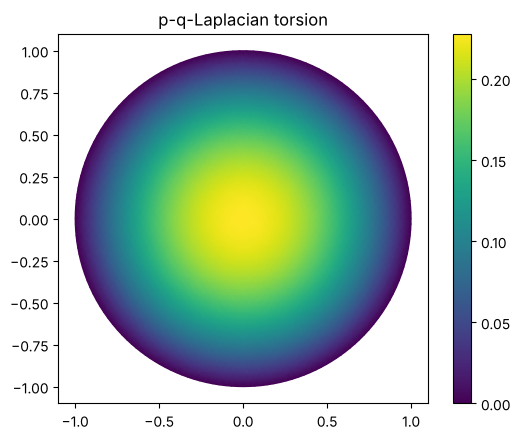

In [11]:
G = pq(2, 4)
mesh = disk_mesh(0.04)
res = GLaplaceSolver(mesh, G, f=1.0, u_D=0.0).solve(tol=1e-9, stop='residual')
u_ex, grad_ex, _ = exact.radial_torsion(G, c=1.0)      # g(|u'|) = c r/2 solved numerically
fem = P1Space(mesh)
print(f"{res.iterations} iterations, converged={res.converged}, {res.time_iter:.1f}s")
print("true relative L2 error =", fem.l2_error(res.u, u_ex), "  gradient L2 error =", fem.grad_error_Lp(res.u, grad_ex, 2.0))
mesh.plot(res.u); plt.title('p-q-Laplacian torsion'); plt.show()

`res.history` stores, per iteration, `rel_u` (relative change of $u$), `residual` ($\|\nabla u-\nu\|_{L^2}/(1+\|\nabla u\|_{L^2})$) and `energy`.
**Choice of $r$:** the iteration is fastest when $r$ is of the order of $g(t)/t$ at the typical gradient size $t$ (for $G=t^p/p$ and $|\nabla u|\approx1$, $r\approx1$; for larger gradients take larger $r$).

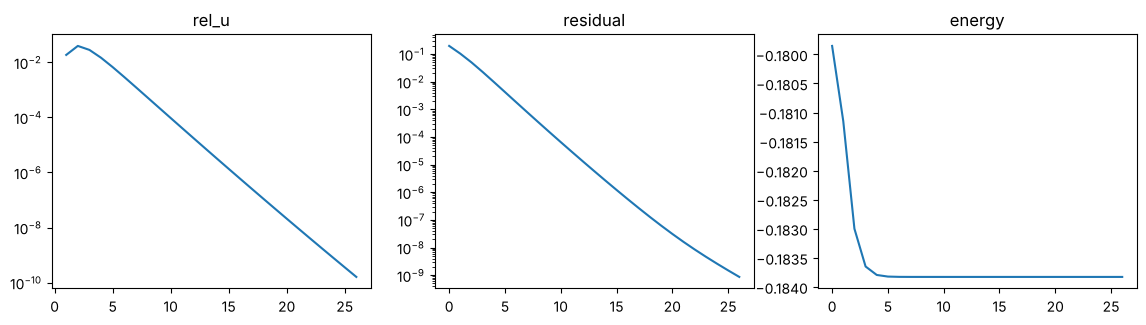

In [12]:
h = res.history
fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].semilogy(h['rel_u']); ax[0].set_title('rel_u'); ax[1].semilogy(h['residual']); ax[1].set_title('residual'); ax[2].plot(h['energy']); ax[2].set_title('energy'); plt.show()

## 4. Torsion on the disk for several $G$ (true errors vs. the exact solution; order in $h$)

In [13]:
cases = {'t^1.5/1.5': PowerLaw(1.5), 't^2/2+t^4/4': pq(2, 4), 't^2 log(1+t)': PLog(2, 1), 'e^t-1-t': Exp()}
print(f"{'G':14s} {'h':>7} {'it':>4} {'L2 rel err':>11} {'order':>6}")
for name, Gf in cases.items():
    u_ex, _, _ = exact.radial_torsion(Gf, 1.0); prev = None
    for h0 in (0.1, 0.05, 0.025):
        m = disk_mesh(h0); r_ = GLaplaceSolver(m, Gf, 1.0, 0.0).solve(tol=1e-9, stop='residual')
        e = P1Space(m).l2_error(r_.u, u_ex)
        print(f"{name:14s} {h0:7.3f} {r_.iterations:4d} {e:11.3e} {'' if prev is None else round(np.log(prev/e)/np.log(2), 2)}"); prev = e

G                    h   it  L2 rel err  order


t^1.5/1.5        0.100  282   8.001e-03 


t^1.5/1.5        0.050  439   1.860e-03 2.11


t^1.5/1.5        0.025  584   4.690e-04 1.99


t^2/2+t^4/4      0.100   29   4.551e-03 


...

t^2 log(1+t)     0.100   37   4.224e-03 


t^2 log(1+t)     0.050   45   9.599e-04 2.14


t^2 log(1+t)     0.025   50   2.446e-04 1.97
e^t-1-t          0.100   28   4.620e-03 


e^t-1-t          0.050   27   1.050e-03 2.14


e^t-1-t          0.025   26   2.683e-04 1.97


## 5. Two-phase problem: $G(x,t)=t^p/p+a(x)\,t^q/q$ with $a\ge0$ vanishing on a sector

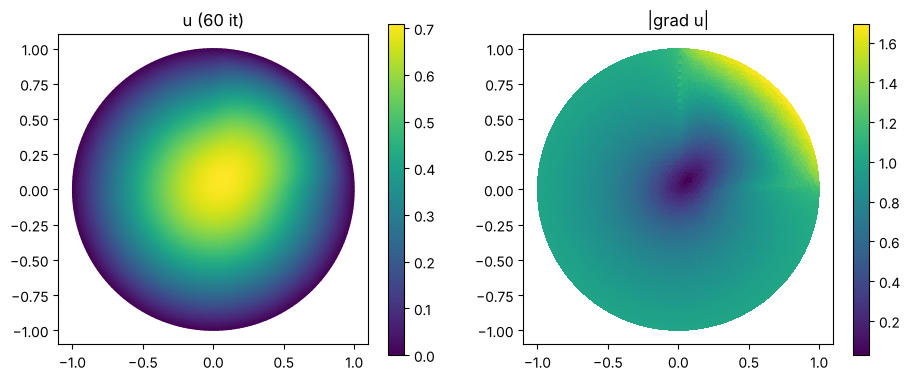

In [14]:
ang = lambda x, y: np.mod(np.arctan2(y, x), 2*np.pi)
a = lambda x, y: np.where((ang(x, y) > 0) & (ang(x, y) < np.pi/2), 0.0, 1.0)
G2 = pq(2, 6, a)
m = disk_mesh(0.03)
r2 = GLaplaceSolver(m, G2, 4.0, 0.0, r=3.0).solve(tol=1e-9, stop='residual')
fem = P1Space(m); gx, gy = fem.gradient(r2.u)
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3))
m.plot(r2.u, ax=ax[0]); ax[0].set_title(f'u ({r2.iterations} it)')
c = ax[1].tripcolor(m.vertices[:, 0], m.vertices[:, 1], m.triangles, facecolors=np.hypot(gx, gy)); plt.colorbar(c, ax=ax[1]); ax[1].set_aspect('equal'); ax[1].set_title('|grad u|')
plt.show()

## 6. $G(t)=e^t-1$: no $\Delta_2$ condition and $g(0^+)=1$ → dead core
Torsion with load $c$: $g(|u'|)=cr/2$ has a solution only where $cr/2>1$; $u$ is flat for $r\le 2/c$.

244 True true rel L2 error 0.0011205086909778263


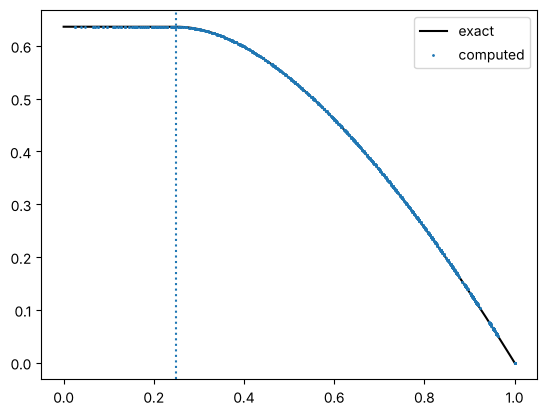

In [15]:
Gx = ExpLiteral(); c = 8.0
u_ex, _, ur = exact.radial_torsion(Gx, c)
m = disk_mesh(0.05)
rx = GLaplaceSolver(m, Gx, c, 0.0, r=30.0).solve(tol=1e-8, max_iter=6000, stop='residual')
print(rx.iterations, rx.converged, 'true rel L2 error', P1Space(m).l2_error(rx.u, u_ex))
rr = np.linspace(0, 1, 300); R = np.hypot(*m.vertices.T)
plt.plot(rr, u_ex(rr, 0*rr), 'k', label='exact'); plt.plot(R, rx.u, '.', ms=2, label='computed'); plt.axvline(2/c, ls=':'); plt.legend(); plt.show()

## 7. Other domains and your own data
```python
mesh = rectangle_mesh(100, 100)                                         # (0,1)^2
mesh = polygon_mesh(outer_xy, holes=[hole_xy], max_area=0.002)           # polygon with holes (needs `triangle`)
mesh = sdf_mesh(lambda P: np.hypot(P[:,0], P[:,1]) - 1, (-1,-1,1,1), h0=0.03)   # signed distance function
mesh = Mesh(vertices, triangles, dirichlet_node_indices)                 # your own arrays (0-based)
mesh = from_txt('vertex_coordinates.txt', 'elem_vertices.txt', 'dirichlet.txt')  # MatLab files (1-based)
mesh = from_meshio('domain.msh')                                         # Gmsh etc.
```
`f`, `u_D` and the weights in `G` can be constants or vectorised functions of `(x, y)`; $G(x,\cdot)$ is sampled at the triangle barycentres.